In [2]:
import pandas as pd
df = pd.read_excel("Volve production data.xlsx", sheet_name="Daily Production Data")
print(df.head())
print(df.columns)

     DATEPRD WELL_BORE_CODE  NPD_WELL_BORE_CODE NPD_WELL_BORE_NAME  \
0 2014-04-07  NO 15/9-F-1 C                7405         15/9-F-1 C   
1 2014-04-08  NO 15/9-F-1 C                7405         15/9-F-1 C   
2 2014-04-09  NO 15/9-F-1 C                7405         15/9-F-1 C   
3 2014-04-10  NO 15/9-F-1 C                7405         15/9-F-1 C   
4 2014-04-11  NO 15/9-F-1 C                7405         15/9-F-1 C   

   NPD_FIELD_CODE NPD_FIELD_NAME  NPD_FACILITY_CODE NPD_FACILITY_NAME  \
0         3420717          VOLVE             369304    MÆRSK INSPIRER   
1         3420717          VOLVE             369304    MÆRSK INSPIRER   
2         3420717          VOLVE             369304    MÆRSK INSPIRER   
3         3420717          VOLVE             369304    MÆRSK INSPIRER   
4         3420717          VOLVE             369304    MÆRSK INSPIRER   

   ON_STREAM_HRS  AVG_DOWNHOLE_PRESSURE  ...  AVG_CHOKE_UOM  AVG_WHP_P  \
0            0.0                0.00000  ...              %    0.0

In [3]:
needed = ["DATEPRD", "NPD_WELL_BORE_NAME", "WELL_TYPE", "ON_STREAM_HRS",
          "AVG_DOWNHOLE_PRESSURE", "AVG_WHP_P", "AVG_CHOKE_SIZE_P",
          "BORE_OIL_VOL", "BORE_WAT_VOL"]
print("Missing columns:", [c for c in needed if c not in df.columns])
print()
print(df["WELL_TYPE"].value_counts())
print()
print(df[df.WELL_TYPE == "OP"]["NPD_WELL_BORE_NAME"].value_counts())


Missing columns: []

WELL_TYPE
OP    9143
WI    6491
Name: count, dtype: int64

NPD_WELL_BORE_NAME
15/9-F-14      3056
15/9-F-12      3056
15/9-F-11      1165
15/9-F-15 D     978
15/9-F-1 C      744
15/9-F-5        144
Name: count, dtype: int64


In [4]:
!pip install xgboost -q
import pandas as pd, numpy as np, matplotlib.pyplot as plt, itertools, os
from xgboost import XGBRegressor
from scipy.optimize import curve_fit
from sklearn.ensemble import IsolationForest
from sklearn.metrics import mean_absolute_percentage_error
os.makedirs("results", exist_ok=True)

df = pd.read_excel("Volve production data.xlsx", sheet_name="Daily Production Data")
df["DATEPRD"] = pd.to_datetime(df["DATEPRD"])
df = df[(df.WELL_TYPE == "OP") & (df.BORE_OIL_VOL > 0) & (df.ON_STREAM_HRS > 0)]
df = df.rename(columns={"NPD_WELL_BORE_NAME": "well"}).sort_values(["well", "DATEPRD"])
df["days"] = df.groupby("well")["DATEPRD"].transform(lambda s: (s - s.min()).dt.days)

FEATS = ["AVG_CHOKE_SIZE_P", "AVG_WHP_P", "AVG_DOWNHOLE_PRESSURE", "ON_STREAM_HRS", "days"]
df = df.dropna(subset=FEATS + ["BORE_OIL_VOL", "BORE_WAT_VOL"])

wells = df.well.value_counts().loc[lambda s: s >= 300].index[:5].tolist()
print("Wells we will use:", wells)
print()
print(df.well.value_counts())

Wells we will use: ['15/9-F-12', '15/9-F-14', '15/9-F-11', '15/9-F-15 D', '15/9-F-1 C']

well
15/9-F-12      2830
15/9-F-14      2717
15/9-F-11      1119
15/9-F-15 D     767
15/9-F-1 C      429
Name: count, dtype: int64


In [5]:
def arps(t, qi, Di, b):
    return qi / np.power(1 + b * Di * t, 1 / b)

mo, mw, rows = {}, {}, []
for w in wells:
    d = df[df.well == w]
    s = int(len(d) * 0.8)
    tr, te = d.iloc[:s], d.iloc[s:]

    # AI model: learns oil from choke, pressures, hours, time
    xo = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05).fit(tr[FEATS], tr.BORE_OIL_VOL)
    ml_mape = mean_absolute_percentage_error(te.BORE_OIL_VOL, xo.predict(te[FEATS])) * 100

    # Old method: decline curve (uses time only)
    try:
        p, _ = curve_fit(arps, tr.days, tr.BORE_OIL_VOL, p0=[tr.BORE_OIL_VOL.max(), 1e-3, 0.5],
                         bounds=([0, 1e-6, 0.01], [1e6, 1, 2]), maxfev=20000)
        arps_mape = np.mean(np.abs((te.BORE_OIL_VOL - arps(te.days, *p)) / te.BORE_OIL_VOL)) * 100
    except Exception:
        arps_mape = np.nan

    rows.append({"well": w, "Arps_MAPE_%": round(arps_mape, 1), "XGB_MAPE_%": round(ml_mape, 1)})

    # Re-train on ALL data (oil model and water model) for the optimization step
    mo[w] = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05).fit(d[FEATS], d.BORE_OIL_VOL)
    mw[w] = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05).fit(d[FEATS], d.BORE_WAT_VOL)

results = pd.DataFrame(rows)
print(results)
results.to_csv("results/model_comparison.csv", index=False)

          well  Arps_MAPE_%  XGB_MAPE_%
0    15/9-F-12         39.6        44.7
1    15/9-F-14        142.5        89.6
2    15/9-F-11        140.4        78.5
3  15/9-F-15 D        552.6       379.7
4   15/9-F-1 C        592.9       151.8


In [6]:
def wmape(y, p):
    return np.sum(np.abs(y - p)) / np.sum(np.abs(y)) * 100

FEATS_NEW = [f for f in FEATS if f != "days"]

rows = []
for w in wells:
    d = df[df.well == w]
    s = int(len(d) * 0.8)
    tr, te = d.iloc[:s], d.iloc[s:]

    # old method: decline curve
    try:
        p, _ = curve_fit(arps, tr.days, tr.BORE_OIL_VOL, p0=[tr.BORE_OIL_VOL.max(), 1e-3, 0.5],
                         bounds=([0, 1e-6, 0.01], [1e6, 1, 2]), maxfev=20000)
        a = wmape(te.BORE_OIL_VOL, arps(te.days, *p))
    except Exception:
        a = np.nan

    # AI with days (what we did before)
    x1 = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05).fit(tr[FEATS], tr.BORE_OIL_VOL)
    b = wmape(te.BORE_OIL_VOL, x1.predict(te[FEATS]))

    # AI without days (new)
    x2 = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05).fit(tr[FEATS_NEW], tr.BORE_OIL_VOL)
    c = wmape(te.BORE_OIL_VOL, x2.predict(te[FEATS_NEW]))

    rows.append({"well": w, "Arps_%": round(a, 1), "XGB_with_days_%": round(b, 1), "XGB_no_days_%": round(c, 1)})

    # retrain on all data, without days, for the optimization step
    mo[w] = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05).fit(d[FEATS_NEW], d.BORE_OIL_VOL)
    mw[w] = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05).fit(d[FEATS_NEW], d.BORE_WAT_VOL)

FEATS = FEATS_NEW
results = pd.DataFrame(rows)
print(results)
results.to_csv("results/model_comparison.csv", index=False)

          well  Arps_%  XGB_with_days_%  XGB_no_days_%
0    15/9-F-12    32.1             35.3           33.2
1    15/9-F-14   123.9             73.8           40.6
2    15/9-F-11    96.5             60.8           46.4
3  15/9-F-15 D    23.1             29.9           21.5
4   15/9-F-1 C    39.3             25.9           41.3


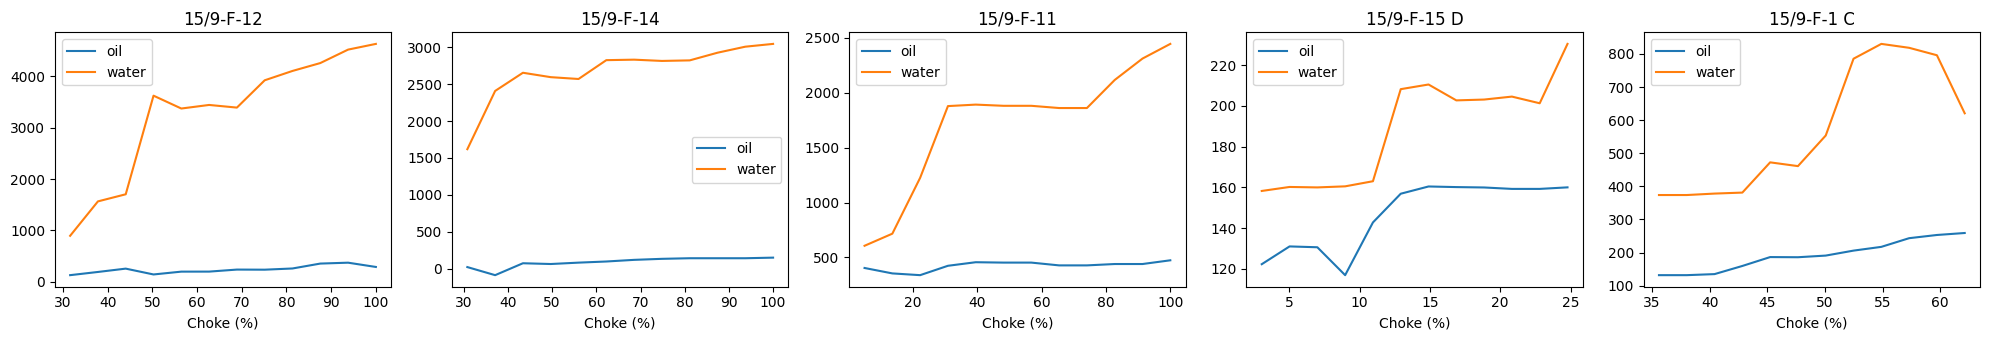

In [7]:
N = 12
opt = {}
fig, axes = plt.subplots(1, len(wells), figsize=(4 * len(wells), 3.5))

for ax, w in zip(np.atleast_1d(axes), wells):
    d = df[df.well == w]
    base = d.iloc[-30:][FEATS].mean()          # recent typical conditions
    lo, hi = d.AVG_CHOKE_SIZE_P.quantile([0.05, 0.95])
    grid = np.linspace(lo, hi, N)              # 12 valve settings to try

    X = pd.DataFrame([base] * N)
    X["AVG_CHOKE_SIZE_P"] = grid               # change only the valve
    now = pd.DataFrame([base])

    opt[w] = dict(grid=grid,
                  oil=mo[w].predict(X), wat=mw[w].predict(X),
                  cur_oil=mo[w].predict(now)[0], cur_wat=mw[w].predict(now)[0],
                  cur_choke=base.AVG_CHOKE_SIZE_P)

    ax.plot(grid, opt[w]["oil"], label="oil")
    ax.plot(grid, opt[w]["wat"], label="water")
    ax.set_title(w); ax.set_xlabel("Choke (%)"); ax.legend()

plt.tight_layout()
plt.savefig("results/choke_sensitivity.png", dpi=150)
plt.show()

Today (model estimate): oil 1019 Sm3/d, water 6726 Sm3/d

Water limit 70% of today: oil 1064 Sm3/d (+4.4% vs today)
Water limit 80% of today: oil 1103 Sm3/d (+8.3% vs today)
Water limit 90% of today: oil 1222 Sm3/d (+19.9% vs today)
Water limit 100% of today: oil 1230 Sm3/d (+20.7% vs today)

          well  current_choke_%  recommended_choke_%     oil_now  \
0    15/9-F-12             31.0                 44.0  135.699997   
1    15/9-F-14             55.5                100.0   80.900002   
2    15/9-F-11             98.8                  5.0  454.799988   
3  15/9-F-15 D             26.0                 14.9  158.699997   
4   15/9-F-1 C             49.7                 62.1  188.899994   

   oil_recommended    water_now  water_recommended  
0       257.899994   896.400024        1704.099976  
1       148.600006  2569.500000        3045.100098  
2       404.399994  2469.899902         606.700012  
3       160.399994   230.600006         210.500000  
4       258.899994   559.599976 

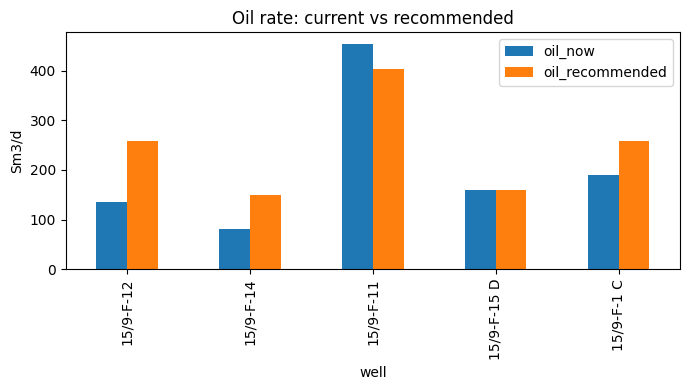

In [8]:
rows_idx = np.arange(len(wells))
oil = np.array([opt[w]["oil"] for w in wells])   # predicted oil at each of the 12 valve settings
wat = np.array([opt[w]["wat"] for w in wells])   # predicted water at each setting
base_oil = sum(opt[w]["cur_oil"] for w in wells)
base_wat = sum(opt[w]["cur_wat"] for w in wells)

def optimize(cap):
    best, best_oil = None, -1
    for combo in itertools.product(range(N), repeat=len(wells)):
        if wat[rows_idx, combo].sum() <= cap:
            o = oil[rows_idx, combo].sum()
            if o > best_oil:
                best, best_oil = combo, o
    return best, best_oil

print(f"Today (model estimate): oil {base_oil:.0f} Sm3/d, water {base_wat:.0f} Sm3/d\n")

# Try different water limits
for f in [0.7, 0.8, 0.9, 1.0]:
    b, o = optimize(base_wat * f)
    if b is None:
        print(f"Water limit {f:.0%} of today: no feasible setting")
    else:
        print(f"Water limit {f:.0%} of today: oil {o:.0f} Sm3/d ({100*(o/base_oil-1):+.1f}% vs today)")

# Detailed result for the main case: no more water than today
best, best_oil = optimize(base_wat * 1.0)
rec = pd.DataFrame({
    "well": wells,
    "current_choke_%": [opt[w]["cur_choke"] for w in wells],
    "recommended_choke_%": [opt[w]["grid"][c] for w, c in zip(wells, best)],
    "oil_now": [opt[w]["cur_oil"] for w in wells],
    "oil_recommended": [opt[w]["oil"][c] for w, c in zip(wells, best)],
    "water_now": [opt[w]["cur_wat"] for w in wells],
    "water_recommended": [opt[w]["wat"][c] for w, c in zip(wells, best)],
}).round(1)
print()
print(rec)
rec.to_csv("results/recommendations.csv", index=False)

rec.set_index("well")[["oil_now", "oil_recommended"]].plot.bar(figsize=(7, 4), title="Oil rate: current vs recommended")
plt.ylabel("Sm3/d"); plt.tight_layout()
plt.savefig("results/optimization_result.png", dpi=150); plt.show()

Choke moves limited to +/-15 points
Water limit 80%: no feasible setting
Water limit 90%: no feasible setting
Water limit 100%: oil 1071 Sm3/d (+5.2% vs today)

          well  current_choke_%  recommended_choke_%     oil_now  \
0    15/9-F-12             31.0                 31.6  135.699997   
1    15/9-F-14             55.5                 56.0   80.900002   
2    15/9-F-11             98.8                 91.4  454.799988   
3  15/9-F-15 D             26.0                 14.9  158.699997   
4   15/9-F-1 C             49.7                 62.1  188.899994   

   oil_recommended    water_now  water_recommended  
0       130.899994   896.400024         896.400024  
1        80.900002  2569.500000        2569.500000  
2       440.399994  2469.899902        2312.199951  
3       160.399994   230.600006         210.500000  
4       258.899994   559.599976         620.599976  


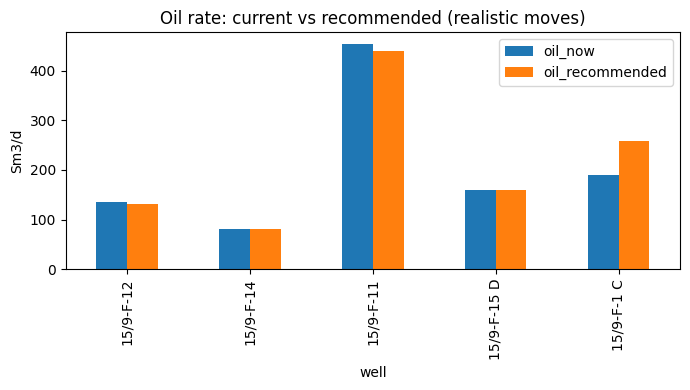

In [9]:
MAXMOVE = 15   # each choke may move at most 15 percentage points from today

allowed = []
for w in wells:
    g, c = opt[w]["grid"], opt[w]["cur_choke"]
    ok = [i for i in range(N) if abs(g[i] - c) <= MAXMOVE]
    allowed.append(ok if ok else [int(np.argmin(abs(g - c)))])

def optimize_safe(cap):
    best, best_oil = None, -1
    for combo in itertools.product(*allowed):
        c = list(combo)
        if wat[rows_idx, c].sum() <= cap:
            o = oil[rows_idx, c].sum()
            if o > best_oil:
                best, best_oil = c, o
    return best, best_oil

print(f"Choke moves limited to +/-{MAXMOVE} points")
for f in [0.8, 0.9, 1.0]:
    b, o = optimize_safe(base_wat * f)
    if b is None:
        print(f"Water limit {f:.0%}: no feasible setting")
    else:
        print(f"Water limit {f:.0%}: oil {o:.0f} Sm3/d ({100*(o/base_oil-1):+.1f}% vs today)")

best, best_oil = optimize_safe(base_wat * 1.0)
rec2 = pd.DataFrame({
    "well": wells,
    "current_choke_%": [opt[w]["cur_choke"] for w in wells],
    "recommended_choke_%": [opt[w]["grid"][c] for w, c in zip(wells, best)],
    "oil_now": [opt[w]["cur_oil"] for w in wells],
    "oil_recommended": [opt[w]["oil"][c] for w, c in zip(wells, best)],
    "water_now": [opt[w]["cur_wat"] for w in wells],
    "water_recommended": [opt[w]["wat"][c] for w, c in zip(wells, best)],
}).round(1)
print()
print(rec2)
rec2.to_csv("results/recommendations_realistic.csv", index=False)

rec2.set_index("well")[["oil_now", "oil_recommended"]].plot.bar(figsize=(7, 4), title="Oil rate: current vs recommended (realistic moves)")
plt.ylabel("Sm3/d"); plt.tight_layout()
plt.savefig("results/optimization_realistic.png", dpi=150); plt.show()

In [10]:
from google.colab import files
!zip -r results.zip results -q
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>